# Pair 3: GraphSAGE vs FAGCN
Fake review account detection on the Amazon graph (CARE-GNN). GraphSAGE averages neighbours (homophily), FAGCN can also use differences to neighbours (heterophily). MLP and GCN are only baselines.

In [1]:
import os, time, copy, random
import scipy.io
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GCNConv, FAConv
from torch_geometric.utils import remove_self_loops
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.model_selection import train_test_split

device = "cuda"   #change to "cpu" if you get out of memory
hidden = 32   #64 does not fit in 8 GB for FAGCN on the full graph
dropout = 0.4
lr = 0.005
wd = 5e-4
epochs = 400
patience = 12
seeds = [0, 1, 2, 3, 4]
relations = ["homo", "upu", "usu", "uvu"]
os.makedirs("results/pair3",exist_ok=True)
os.makedirs("results/summary",exist_ok=True)

In [2]:
data = scipy.io.loadmat("data/amazon/Amazon.mat")
x = torch.tensor(data["features"].toarray(),dtype=torch.float)
y = torch.tensor(data["label"].flatten(),dtype=torch.long)
edges = {}
for r in relations:
    key = "net_"+r
    if r=="homo":
        key = "homo"
    m = data[key].tocoo()
    e = torch.tensor(np.vstack([m.row,m.col]),dtype=torch.long)
    e, _ = remove_self_loops(e)
    edges[r] = e

labelled = np.arange(3305,len(y))   #first 3305 users have no label
labels = y[3305:].numpy()

stats = []
for r, e in edges.items():
    src, dst = e
    src_ok = src>=3305
    dst_ok = dst>=3305
    both = src_ok & dst_ok
    same = (y[src][both]==y[dst][both]).float().mean().item()
    fraud = both & (y[src]==1)
    fraud_same = (y[dst][fraud]==1).float().mean().item()
    stats.append([r, e.shape[1], same, fraud_same])
stats = pd.DataFrame(stats,columns=["relation","edges","edge_homophily","fraud_homophily"])
stats.to_csv("results/summary/pair3_graph_stats.csv",index=False)
print(stats)

  relation    edges  edge_homophily  fraud_homophily
0     homo  8796784        0.948772         0.085874
1      upu   351216        0.785218         0.176702
2      usu  7132958        0.955624         0.067187
3      uvu  2073474        0.961085         0.064192


In [3]:
class Net(nn.Module):
    def __init__(self,kind,d):
        super().__init__()
        self.kind = kind
        if kind=="fagcn":
            self.lin = nn.Linear(d,hidden)
            self.c1 = FAConv(hidden,eps=0.3,dropout=dropout)
            self.c2 = FAConv(hidden,eps=0.3,dropout=dropout)
        elif kind=="graphsage":
            self.c1 = SAGEConv(d,hidden)
            self.c2 = SAGEConv(hidden,hidden)
        elif kind=="gcn":
            self.c1 = GCNConv(d,hidden)
            self.c2 = GCNConv(hidden,hidden)
        else:
            self.c1 = nn.Linear(d,hidden)
            self.c2 = nn.Linear(hidden,hidden)
        self.out = nn.Linear(hidden,2)

    def forward(self,x,e):
        if self.kind=="fagcn":
            x = F.dropout(x,dropout,self.training)
            h0 = F.relu(self.lin(x))
            h = F.dropout(h0,dropout,self.training)
            h = self.c1(h,h0,e)
            h = self.c2(h,h0,e)
            h = F.dropout(h,dropout,self.training)
        else:
            h = x
            for conv in [self.c1, self.c2]:
                if self.kind=="mlp":
                    h = conv(h)
                else:
                    h = conv(h,e)
                h = F.relu(h)
                h = F.dropout(h,dropout,self.training)
        h = self.out(h)
        return h



In [4]:
def predict(model,x,e):
    model.eval()
    with torch.no_grad():
        out = model(x,e)
    p = F.softmax(out,dim=1)[:,1]
    p = p.cpu().numpy()
    return p

def train(kind,x,y,e,tr,va,seed):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    model = Net(kind,x.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(),lr=lr,weight_decay=wd)
    n_fraud = (y[tr]==1).sum().item()
    n_normal = (y[tr]==0).sum().item()
    w = torch.tensor([1.0,n_normal/n_fraud],device=device)   #class weights
    yv = y[va].cpu().numpy()
    best = -1
    bad = 0
    for ep in range(epochs):
        model.train()
        opt.zero_grad()
        out = model(x,e)
        loss = F.cross_entropy(out[tr],y[tr],weight=w)
        loss.backward()
        opt.step()
        if ep%5==0:   #early stopping on validation AUPRC
            p = predict(model,x,e)
            ap = average_precision_score(yv,p[va.cpu().numpy()])
            if ap>best:
                best = ap
                bad = 0
                state = copy.deepcopy(model.state_dict())
            else:
                bad += 1
                if bad>=patience:
                    break
    model.load_state_dict(state)
    n_ep = ep+1
    return model, n_ep

def evaluate(yt,p,thr):
    n = len(yt)
    k = int(np.ceil(0.05*n))   #moderators check the top 5%
    top = np.argsort(-p)[:k]
    pred = (p>=thr).astype(int)
    scores = {}
    scores["auroc"] = roc_auc_score(yt,p)
    scores["auprc"] = average_precision_score(yt,p)
    scores["macro_f1"] = f1_score(yt,pred,average="macro")
    scores["precision_at_5%"] = yt[top].mean()
    scores["recall_at_5%"] = yt[top].sum()/yt.sum()
    return scores

## Experiments
40/20/40 split, 5 seeds. Main = combined graph, plus each relation alone, a camouflage test (extra edges from test fraudsters to normal users) and degree groups.

In [5]:
results = []
camo = []
groups = []
deg = torch.bincount(edges["homo"][0],minlength=len(y)).numpy()
yd = y.to(device)

for seed in seeds:
    tr, rest = train_test_split(labelled,train_size=0.4,stratify=labels,random_state=seed)
    va, te = train_test_split(rest,train_size=1/3,stratify=y[rest].numpy(),random_state=seed)
    mean = x[tr].mean(0)
    std = x[tr].std(0)+1e-6
    xn = (x-mean)/std   #normalise with the training set only
    xn = xn.to(device)
    yt = y[te].numpy()
    yv = y[va].numpy()
    tr_t = torch.tensor(tr,device=device)
    va_t = torch.tensor(va,device=device)

    for r in relations:
        e = edges[r].to(device)
        for kind in ["graphsage", "fagcn", "gcn", "mlp"]:
            if kind=="mlp" and r!="homo":
                continue
            torch.cuda.reset_peak_memory_stats()
            t = time.time()
            model, n_ep = train(kind,xn,yd,e,tr_t,va_t,seed)
            train_s = time.time()-t
            memory = torch.cuda.max_memory_allocated()/1024**2
            t = time.time()
            p = predict(model,xn,e)
            infer_s = time.time()-t

            #threshold with the best macro F1 on validation
            best_f1 = 0
            thr = 0.5
            for g in np.arange(0.02,0.99,0.02):
                pred = (p[va]>=g).astype(int)
                f1 = f1_score(yv,pred,average="macro")
                if f1>best_f1:
                    best_f1 = f1
                    thr = g

            sc = evaluate(yt,p[te],thr)
            row = {"seed": seed, "relation": r, "model": kind, "epochs": n_ep, "train_s": train_s, "inference_s": infer_s, "memory_mb": memory}
            row.update(sc)
            results.append(row)
            print(seed,r,kind,"AUROC",round(sc["auroc"],4),"AUPRC",round(sc["auprc"],4))

            if r=="homo":
                d = deg[te]
                q1, q2 = np.quantile(d,[1/3,2/3])
                low = d<=q1
                high = d>q2
                mid = ~low & ~high
                masks = {"low": low, "mid": mid, "high": high}
                for name, mask in masks.items():
                    if yt[mask].sum()>0:
                        ap = average_precision_score(yt[mask],p[te][mask])
                        groups.append([seed, kind, name, ap])

            if r=="homo" and kind!="mlp":
                g = torch.Generator().manual_seed(seed)
                fraud = torch.tensor(te[yt==1])
                normal = torch.tensor(labelled[labels==0])
                for k in [0, 5, 20]:
                    src = fraud.repeat_interleave(k)
                    pick = torch.randint(len(normal),(len(src),),generator=g)
                    dst = normal[pick]
                    e2 = torch.cat([edges["homo"],torch.stack([src,dst]),torch.stack([dst,src])],dim=1)
                    p2 = predict(model,xn,e2.to(device))
                    row = {"seed": seed, "model": kind, "camouflage_edges": k}
                    row.update(evaluate(yt,p2[te],thr))
                    camo.append(row)
            del model
            torch.cuda.empty_cache()

results = pd.DataFrame(results)
camo = pd.DataFrame(camo)
groups = pd.DataFrame(groups,columns=["seed","model","group","auprc"])
results.to_csv("results/pair3/results_per_seed.csv",index=False)
camo.to_csv("results/pair3/camouflage.csv",index=False)
groups.to_csv("results/pair3/degree_groups.csv",index=False)

0 homo graphsage AUROC 0.9779 AUPRC 0.8905
0 homo fagcn AUROC 0.9656 AUPRC 0.8461
0 homo gcn AUROC 0.8996 AUPRC 0.5603
0 homo mlp AUROC 0.9751 AUPRC 0.8929
0 upu graphsage AUROC 0.9673 AUPRC 0.8795
0 upu fagcn AUROC 0.9588 AUPRC 0.8452
0 upu gcn AUROC 0.877 AUPRC 0.5808
0 usu graphsage AUROC 0.9723 AUPRC 0.892
0 usu fagcn AUROC 0.9652 AUPRC 0.8409
0 usu gcn AUROC 0.8924 AUPRC 0.5684
0 uvu graphsage AUROC 0.9708 AUPRC 0.8795
0 uvu fagcn AUROC 0.9546 AUPRC 0.8305
0 uvu gcn AUROC 0.9091 AUPRC 0.6133
1 homo graphsage AUROC 0.9779 AUPRC 0.909
1 homo fagcn AUROC 0.9585 AUPRC 0.8333
1 homo gcn AUROC 0.8959 AUPRC 0.5617
1 homo mlp AUROC 0.9736 AUPRC 0.9075
1 upu graphsage AUROC 0.9674 AUPRC 0.8899
1 upu fagcn AUROC 0.957 AUPRC 0.8566
1 upu gcn AUROC 0.8974 AUPRC 0.6091
1 usu graphsage AUROC 0.976 AUPRC 0.9068
1 usu fagcn AUROC 0.9657 AUPRC 0.8517
1 usu gcn AUROC 0.8872 AUPRC 0.5624
1 uvu graphsage AUROC 0.9612 AUPRC 0.8928
1 uvu fagcn AUROC 0.952 AUPRC 0.8607
1 uvu gcn AUROC 0.9006 AUPRC 0.611

## Results (mean and std over 5 seeds)

                     auroc           auprc         macro_f1          \
                      mean     std    mean     std     mean     std   
relation model                                                        
homo     fagcn      0.9673  0.0056  0.8567  0.0171   0.8903  0.0044   
         gcn        0.9000  0.0065  0.5733  0.0303   0.7610  0.0173   
         graphsage  0.9788  0.0014  0.9112  0.0125   0.9234  0.0095   
         mlp        0.9761  0.0018  0.9090  0.0100   0.9226  0.0082   
upu      fagcn      0.9591  0.0015  0.8552  0.0067   0.8906  0.0093   
         gcn        0.8934  0.0097  0.5898  0.0187   0.7461  0.0137   
         graphsage  0.9724  0.0052  0.8982  0.0129   0.9195  0.0091   
usu      fagcn      0.9693  0.0038  0.8584  0.0148   0.8876  0.0088   
         gcn        0.8933  0.0054  0.5749  0.0170   0.7641  0.0133   
         graphsage  0.9759  0.0044  0.9130  0.0135   0.9265  0.0083   
uvu      fagcn      0.9562  0.0030  0.8490  0.0132   0.8905  0.0079   
      

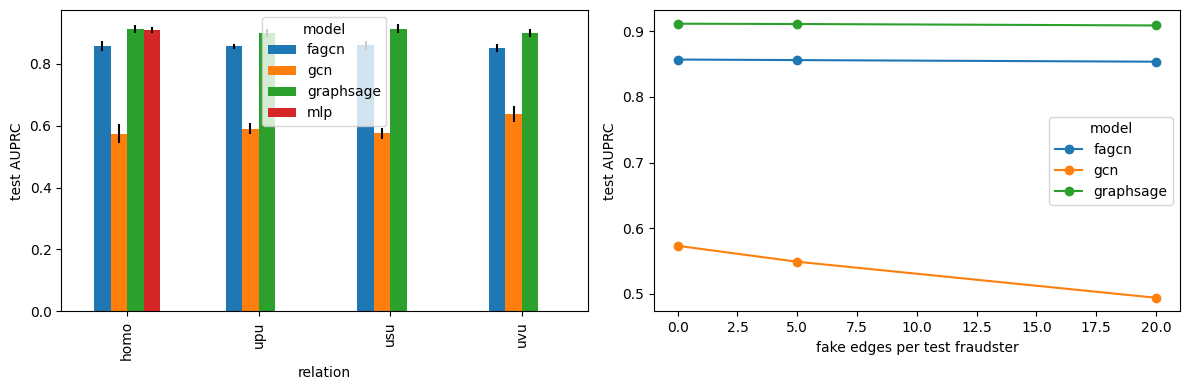

In [6]:
cols = ["auroc", "auprc", "macro_f1", "precision_at_5%", "recall_at_5%", "train_s", "inference_s", "memory_mb"]
summary = results.groupby(["relation","model"])[cols].agg(["mean","std"]).round(4)
camo_summary = camo.groupby(["model","camouflage_edges"])[["auroc","auprc","precision_at_5%"]].agg(["mean","std"]).round(4)
group_summary = groups.groupby(["model","group"]).auprc.agg(["mean","std"]).round(4)
summary.to_csv("results/summary/pair3_summary.csv")
camo_summary.to_csv("results/summary/pair3_camouflage.csv")
group_summary.to_csv("results/summary/pair3_degree_groups.csv")
print(summary)
print(camo_summary)
print(group_summary)

fig, ax = plt.subplots(1,2,figsize=(12,4))
auprc = results.pivot_table(index="relation",columns="model",values="auprc",aggfunc="mean")
auprc_std = results.pivot_table(index="relation",columns="model",values="auprc",aggfunc="std")
auprc.loc[relations].plot.bar(ax=ax[0],yerr=auprc_std.loc[relations])
ax[0].set_ylabel("test AUPRC")
c = camo.pivot_table(index="camouflage_edges",columns="model",values="auprc",aggfunc="mean")
c.plot(ax=ax[1],marker="o")
ax[1].set_xlabel("fake edges per test fraudster")
ax[1].set_ylabel("test AUPRC")
plt.tight_layout()
plt.savefig("results/summary/pair3_results.png",dpi=200)
plt.show()